In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/My Drive/2Tresample_data.csv')

In [ ]:
df.columns

Index(['timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs',
       'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers',
       'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses',
       'Severity', 'Failure', 'Hours_till_Failure'],
      dtype='object')

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

In [ ]:
# Drop 'timestamp' column
df = df.drop(['timestamp','Severity','Hours_till_Failure'], axis=1)

# Define features and target for classification
X = df.drop(columns=['Failure'])
y = df['Failure']  # Assuming 'Failure' is binary (0 or 1)

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape X for TCN input (samples, timesteps, features)
timesteps = 10
X_seq = []
y_seq = []

for i in range(len(X_scaled) - timesteps):
    X_seq.append(X_scaled[i:i + timesteps])
    y_seq.append(y.iloc[i + timesteps])  # Use unscaled binary y values

X_seq, y_seq = np.array(X_seq), np.array(y_seq)

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.2, random_state=42)

In [ ]:
# Build the TCN model for classification
model = Sequential([
    Conv1D(filters=64, kernel_size=2, padding='causal', activation='relu', dilation_rate=1, input_shape=(X_train.shape[1], X_train.shape[2])),
    Conv1D(filters=64, kernel_size=2, padding='causal', activation='relu', dilation_rate=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')  # Output layer for binary classification
])

# Compile the model with binary_crossentropy loss and accuracy metric
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 10, 64)         │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 10, 64)         │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        41,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,329 (200.50 KB)

 Trainable params: 51,329 (200.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Initialize early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',    # Track validation loss
    patience=10,           # Stop after 10 epochs of no improvement
    restore_best_weights=True  # Restore model weights from the epoch with the lowest validation loss
)

# Train the model
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)

Epoch 1/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9854 - loss: 0.0368 - val_accuracy: 0.9962 - val_loss: 0.0089
Epoch 2/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.9963 - loss: 0.0102 - val_accuracy: 0.9955 - val_loss: 0.0101
Epoch 3/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9965 - loss: 0.0087 - val_accuracy: 0.9854 - val_loss: 0.0216
Epoch 4/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9960 - loss: 0.0089 - val_accuracy: 0.9966 - val_loss: 0.0062
Epoch 5/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9973 - loss: 0.0070 - val_accuracy: 0.9988 - val_loss: 0.0048
Epoch 6/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9973 - loss: 0.0071 - val_accuracy: 0.9970 - val_loss: 0.0059
Epoch 7/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9978 - loss: 0.0061 - val_accuracy: 0.9975 - val_loss: 0.0065
Epoch 8/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9966 - loss: 0

In [ ]:
# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f'Test Loss (Binary Crossentropy): {test_loss}')
print(f'Test Accuracy: {test_accuracy}')

# Predict the classes on the test set
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype("int32")  # Convert probabilities to class labels

# Import metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate additional metrics
precision = precision_score(y_test, y_pred_classes, average='weighted')  # Use 'micro', 'macro', or 'weighted' for multi-class
recall = recall_score(y_test, y_pred_classes, average='weighted')
f1 = f1_score(y_test, y_pred_classes, average='weighted')

# Print the metrics
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1-Score: {f1:.4f}')

791/791 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9994 - loss: 0.0029
Test Loss (Binary Crossentropy): 0.003386276075616479
Test Accuracy: 0.9990119934082031
791/791 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
Precision: 0.9990
Recall: 0.9990
F1-Score: 0.9990


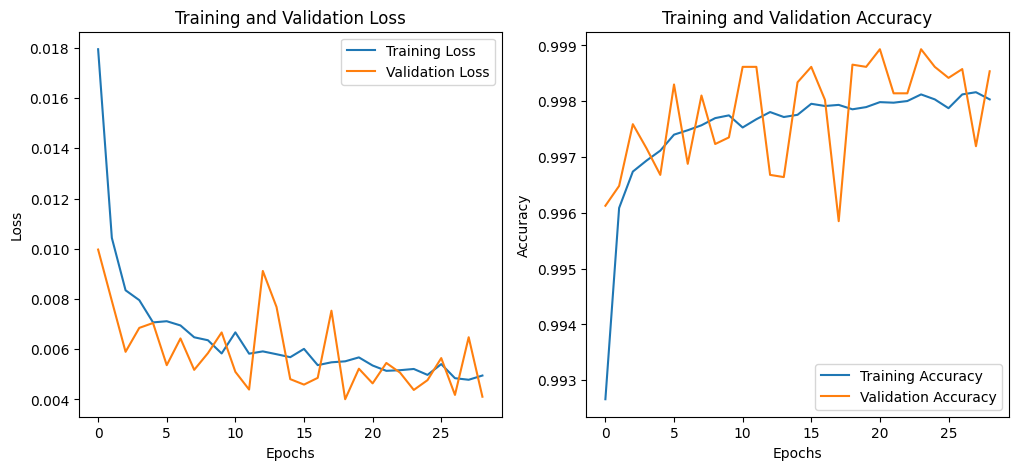

In [ ]:
# Plotting the loss and accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Drop 'timestamp' column
df = df.drop(['timestamp'], axis=1)

In [ ]:
# Split the data into features and target
X = df.drop(columns=['Hours_till_Failure'])
y = df['Hours_till_Failure']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape y to a 2D array for scaling
y_2d = y.values.reshape(-1, 1)  # Reshape to (n_samples, 1)
y_scaled = scaler.fit_transform(y_2d)  # Now you can scale y
y_scaled = y_scaled.ravel()  # Convert back to 1D after scaling if needed

# Reshape X for TCN input (samples, timesteps, features)
# Here, you can choose the number of timesteps. A common choice is 10.
timesteps = 10
X_seq = []
y_seq = []

for i in range(len(X_scaled) - timesteps):
    X_seq.append(X_scaled[i:i + timesteps])
    y_seq.append(y_scaled[i + timesteps])  # Use the scaled y values

X_seq, y_seq = np.array(X_seq), np.array(y_seq)

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.2, random_state=42)

In [ ]:
y_scaled.shape

(126527,)

In [ ]:
X_seq.shape

(126517, 10, 17)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build the TCN model
model = Sequential([
    Conv1D(filters=64, kernel_size=2, padding='causal', activation='relu', dilation_rate=1,  input_shape=(X_train.shape[1], X_train.shape[2])),
    Conv1D(filters=64, kernel_size=2, padding='causal', activation='relu', dilation_rate=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1)  # Output layer for regression
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error')

# Print model summary
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)                    │ (None, 10, 64)              │           2,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 10, 64)              │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 640)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │          41,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 51,585 (201.50 KB)

 Trainable params: 51,585 (201.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Initialize early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',    # Track validation loss
    patience=10,           # Stop after 10 epochs of no improvement
    restore_best_weights=True  # Restore model weights from the epoch with the lowest validation loss
)

# Train the model
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test), callbacks=[early_stopping], verbose=1)

Epoch 1/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - loss: 0.4420 - val_loss: 0.2813
Epoch 2/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - loss: 0.2614 - val_loss: 0.1964
Epoch 3/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 0.2092 - val_loss: 0.1716
Epoch 4/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 0.1850 - val_loss: 0.1629
Epoch 5/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - loss: 0.1686 - val_loss: 0.1650
Epoch 6/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 0.1605 - val_loss: 0.1441
Epoch 7/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - loss: 0.1554 - val_loss: 0.1441
Epoch 8/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - loss: 0.1470 - val_loss: 0.1388
Epoch 9/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - loss: 0.1422 - val_loss: 0.1354
Epoch 10/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - loss: 0.1416 - val_loss: 0.1275
Epoch 11/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - loss: 0.1373 - val_loss: 0.1241
Epoch 12/50
1582/15

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
# Evaluate the model on the test data
test_loss = model.evaluate(X_test, y_test)
print(f'Test Loss (Mean Squared Error): {test_loss}')

# Predicting on the test set
y_pred = model.predict(X_test).flatten()  # Flattening to match true labels' shape

# Evaluate with MAE and R² Score
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"R² Score: {r2}")

791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0923
Test Loss (Mean Squared Error): 0.09020640701055527
791/791 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step
Mean Absolute Error (MAE): 0.2073599653977979
R² Score: 0.9105791644766889


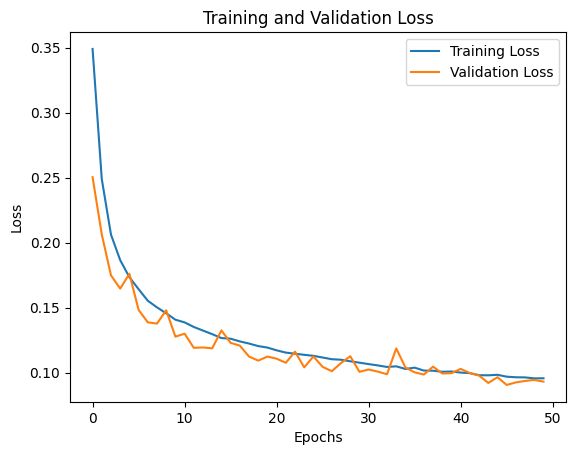

In [ ]:
import matplotlib.pyplot as plt
# Plotting the loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
y_test

array([-0.9968917 , -0.53807684, -0.9968917 , ...,  0.30937567,
       -0.9968917 , -0.00737069])

In [ ]:
y_pred

array([[-0.9984237 ],
       [-0.5358153 ],
       [-1.0018665 ],
       ...,
       [ 0.0274699 ],
       [-1.0127107 ],
       [-0.01277191]], dtype=float32)